# Observing windows and eclipse timing

A period search can only use the eclipses we happened to observe. What survives when the same timing signal is sampled through separated observing windows?

We assume a sinusoidal timing delay with amplitude 35 s and period 420 days. Hypothetical eclipses occur every 2.5 days across a 1200-day interval. Independent Gaussian timing noise uses Chronos's `etv_noise()` formula with eclipse depth 0.1, relative flux noise $10^{-4}$, and eclipse duration 0.15 day. The calculation below reports the resulting timing uncertainty.

We compare all synthetic observations with three artificial windows spanning days 0-180, 500-720, and 1000-1180. These windows are not TESS sector dates. The signal is an assumed sinusoid rather than an integrated circumbinary orbit, and the example supplies no observed data or survey-recovery estimate.

,Sampling,Observations,Recovered period [day],Injected period [day]
0,All synthetic observations,480,419.4,420.0
1,Three synthetic windows,235,419.9,420.0


The assumed single-eclipse timing uncertainty is 6.48 s.

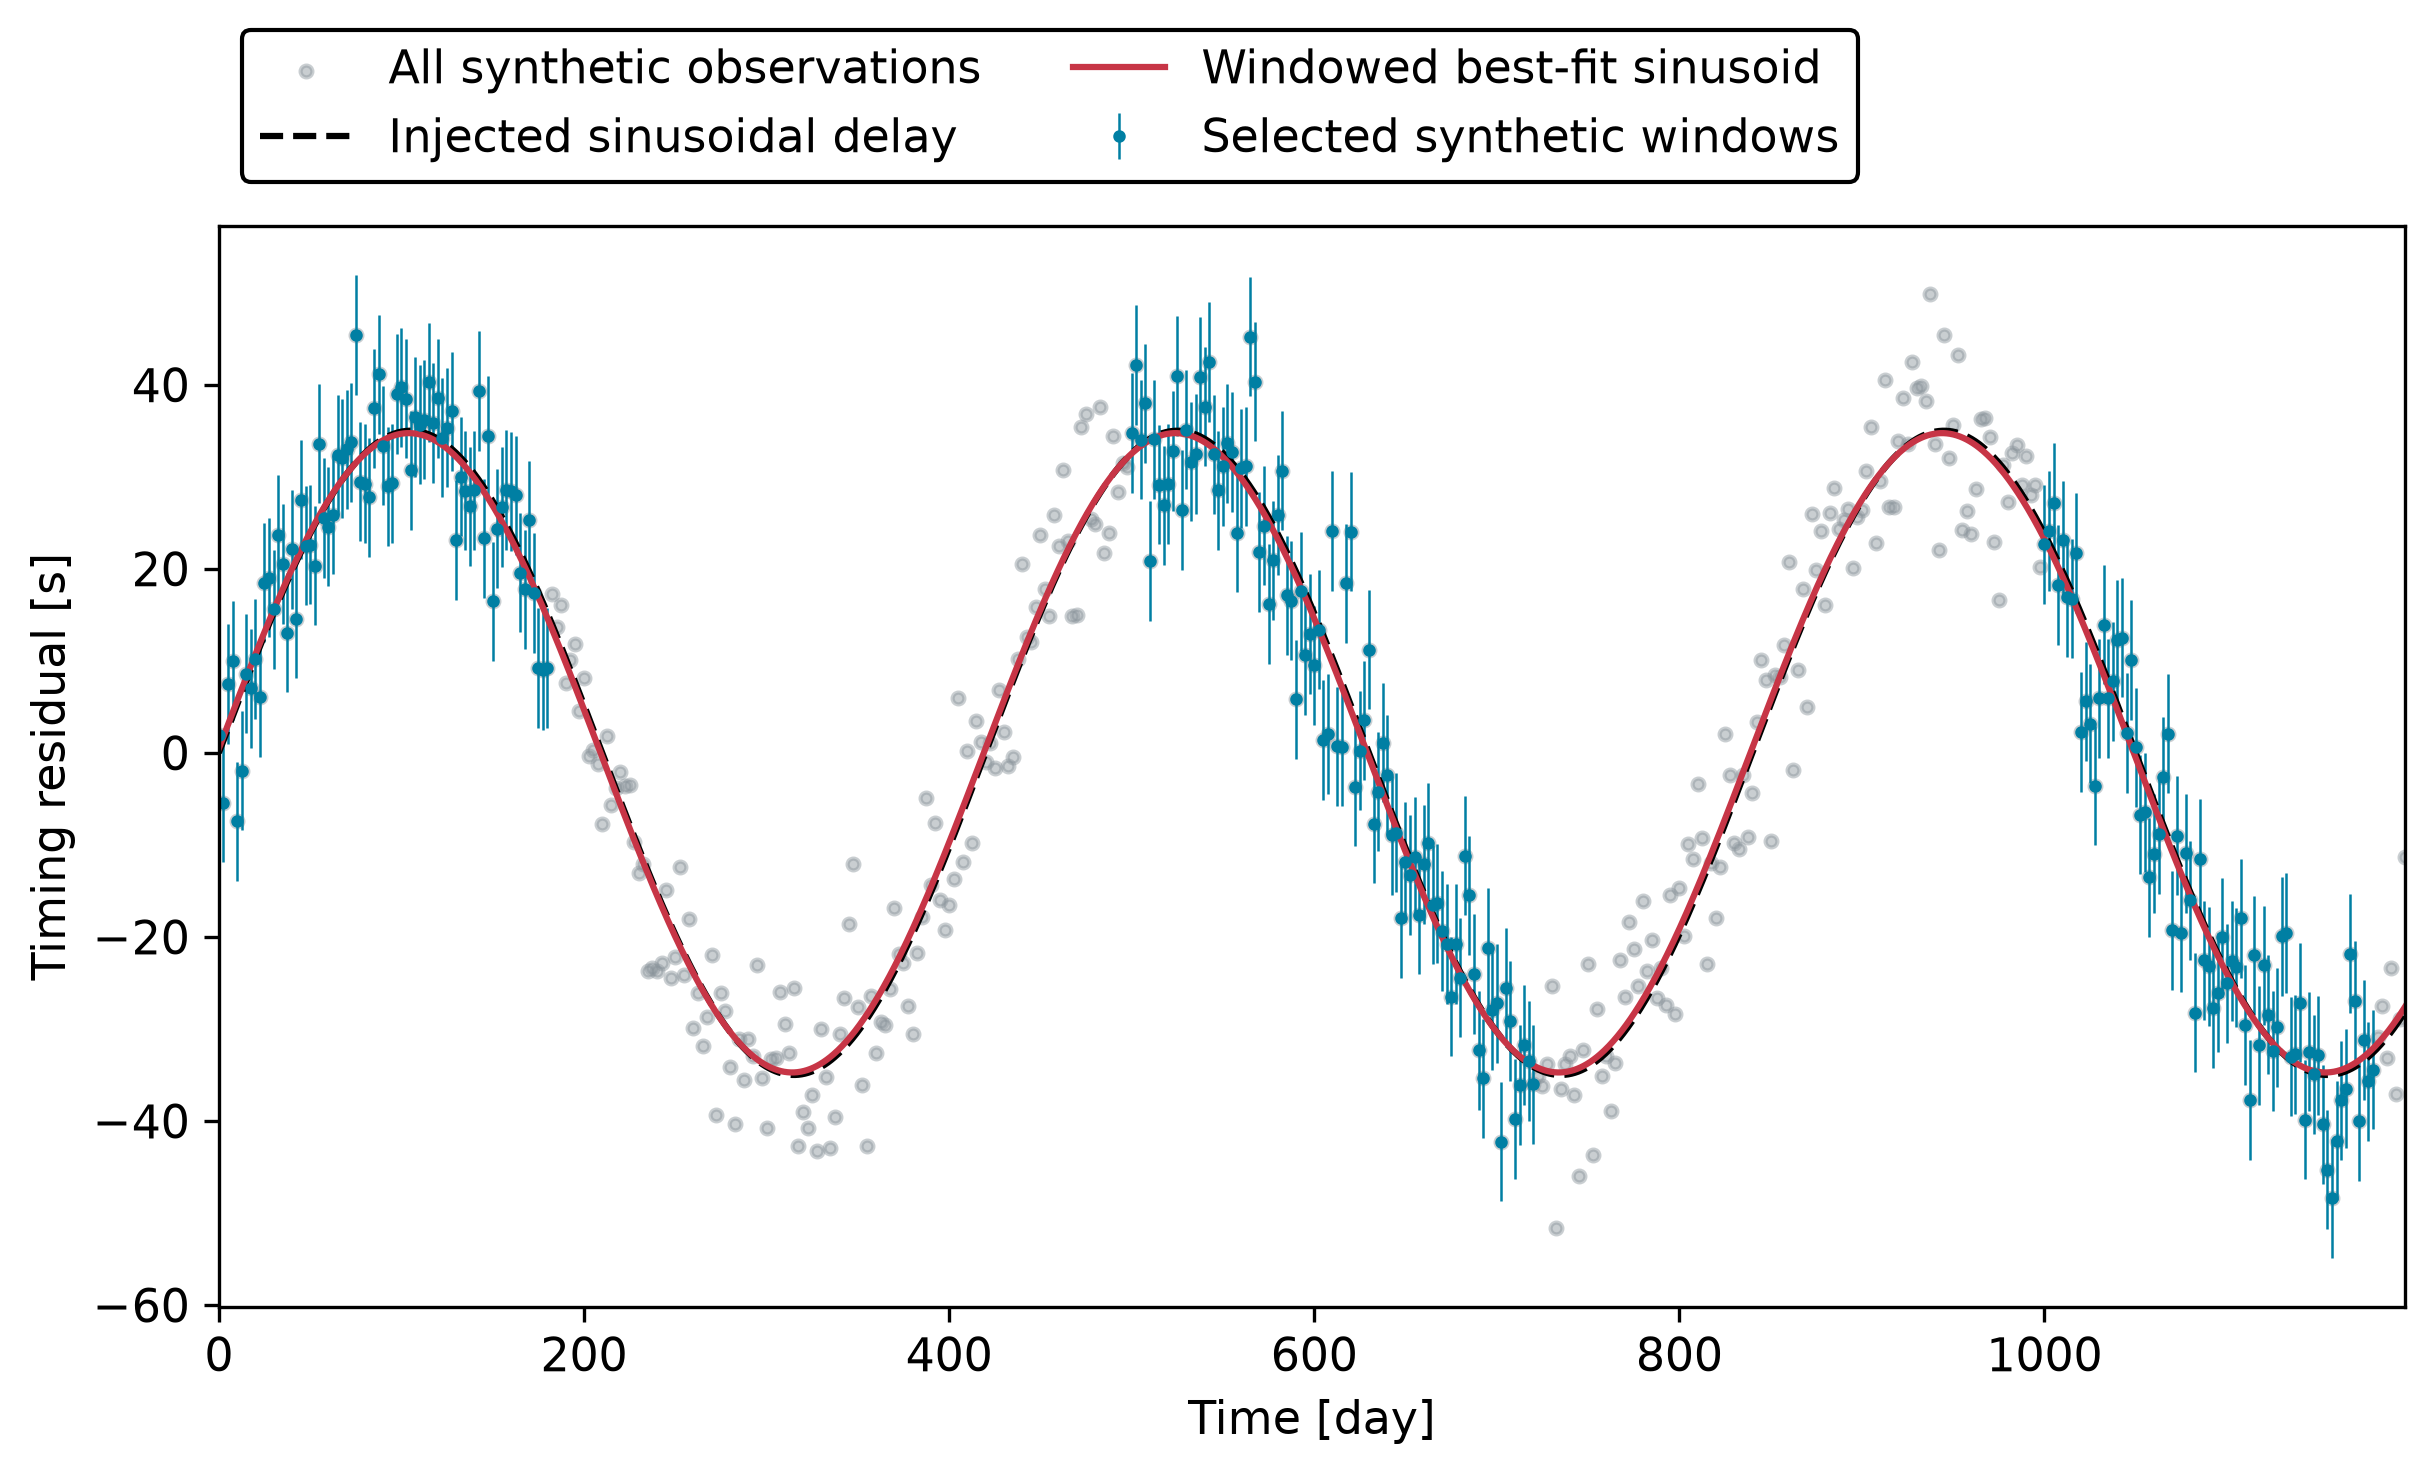

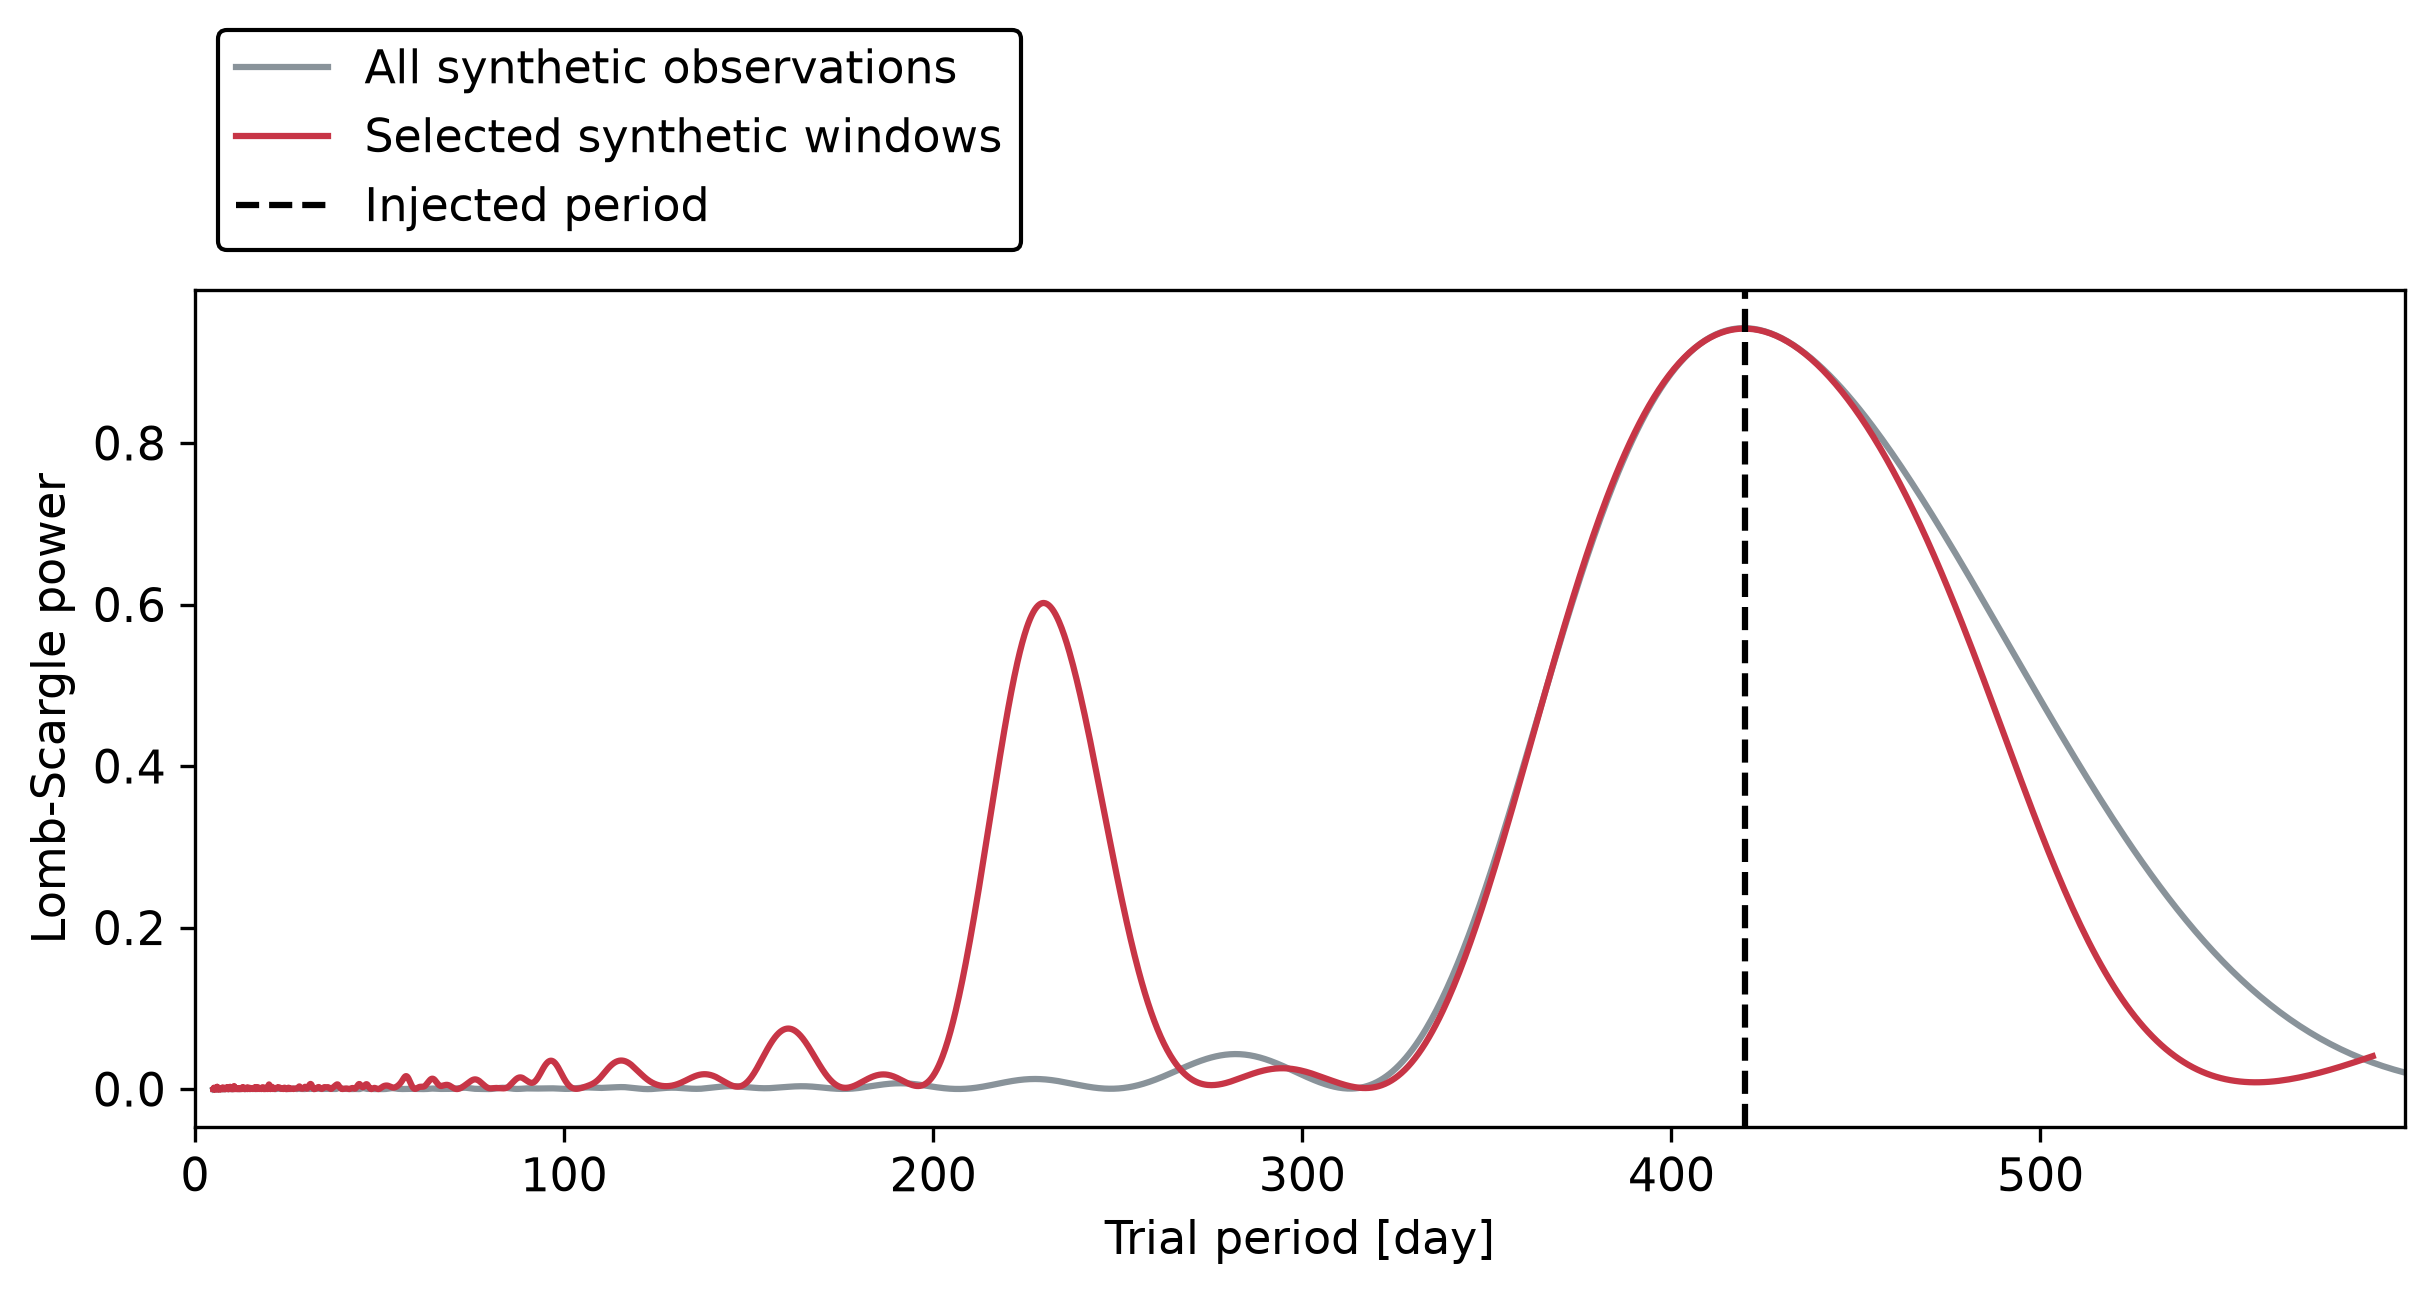

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

candidates = (Path.cwd(), Path.cwd().parent, Path.cwd() / "astromusers" / "chronos")
repository = next(path for path in candidates if (path / "etv_sampler.py").is_file())
for directory in (repository, repository / "examples"):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))

from windowed_timing import simulate_timing_example, plot_timing_example

result = simulate_timing_example(seed=42)
summary = pd.DataFrame({
    "Sampling": ["All synthetic observations", "Three synthetic windows"],
    "Observations": [len(result["time_days"]), int(result["selected"].sum())],
    "Recovered period [day]": [result["complete_search"]["period_days"], result["windowed_search"]["period_days"]],
    "Injected period [day]": [result["period_days"], result["period_days"]],
})
display(summary.round(1))
display(Markdown(f"The assumed single-eclipse timing uncertainty is {result['timing_error_seconds']:.2f} s."))

figure_paths = plot_timing_example(result, interactive=True)
display(Image(filename=str(figure_paths["timing"]), alt="Synthetic timing residuals over the full observation baseline, showing all observations, window-selected observations, the injected sinusoid, and the fitted sinusoid."))
display(Image(filename=str(figure_paths["periodogram"]), alt="Chronos periodograms for continuous and window-selected synthetic sampling, with the injected 420-day period marked."))

## Reading the comparison

The timing-noise estimate, window mask, and Lomb-Scargle search call the same functions used by `etv_recovery()`. The frequency grid retains that workflow's original bounds. Its longest searched period is half the observed baseline, and its shortest is twice the minimum spacing between observations. Gaps can introduce competing peaks. The strongest peak alone establishes neither detection significance nor a unique orbit.

The figures show the full synthetic observation baseline. The fitted curve uses the window-selected observations, while the periodogram compares that selection with continuous synthetic sampling.

## The full orbit workflow

This component example does not run Chronos's full orbit-injection workflow. That workflow additionally needs `TESS_orbit_times.csv`, `rebound_model`, `lite_delay`, `tess_stars2px`, and `ticgen`, which are not supplied by this checkout. We make no claim here about population completeness, real TESS timing measurements, or physical constraints on circumbinary planets.